<h1>Stochastic Gradient Descent</h1>

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import add_dummy_feature


In [23]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick',labelsize=10)


#Nube de puntos

In [24]:
m = 200

rng = np.random.default_rng(seed=42)

X=2*rng.random((m,1))
y = 4 + 3*X + rng.standard_normal((m,1))


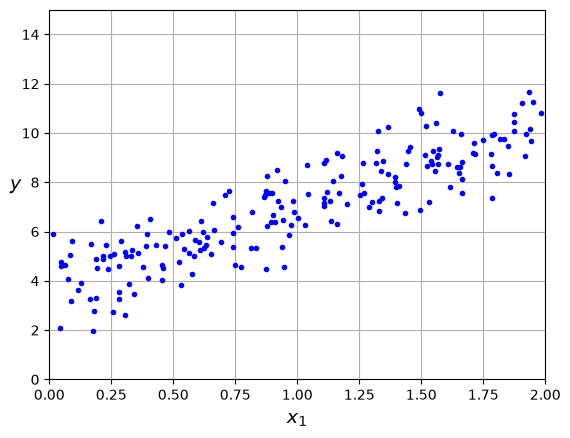

In [25]:
plt.plot(X, y, 'b.')

plt.xlabel('$x_1$')
plt.ylabel('$y$', rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()


In [26]:
X_b = add_dummy_feature(X)
X_b[:5]


array([[1.        , 1.5479121 ],
       [1.        , 0.87775688],
       [1.        , 1.71719584],
       [1.        , 1.39473606],
       [1.        , 0.1883547 ]])

#Stochastic Gradient Descent

In [27]:
# aqui en vez de usar todo X_b como en batch en cada paso agarro solo uno al azar para calcular el gradiente.

n_epochs = 50
t0, t1 = 5, 50 # hiperparametros 

def learning_schedule(t):
    return t0/(t+t1)


In [28]:
rng = np.random.default_rng (seed = 42 );


In [29]:
theta = rng.standard_normal((2,1))
theta


array([[ 0.30471708],
       [-1.03998411]])

In [30]:
n_iterations = n_epochs * m
J_log = np.zeros(n_iterations)

iteration = 0
for epoch in range(n_epochs):
    for i in range(m):
        random_index = rng.integers(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]

        J_log[iteration] = ((X_b@theta-y)**2).mean() #costo con todo el dataset

        gradients = 2 * xi.T @ (xi@theta - yi) #gradiente solo con xi,yi DERIVADA
        eta = learning_schedule(epoch*m + i)
        theta = theta - eta*gradients

        iteration += 1

theta


array([[3.69826475],
       [3.30748311]])

<function matplotlib.pyplot.show(close=None, block=None)>

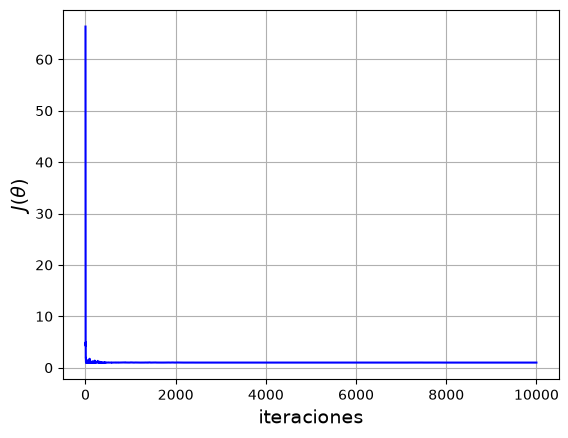

In [31]:
plt.plot(np.arange(n_iterations), J_log, 'b-')
plt.xlabel('iteraciones')
plt.ylabel(r'$J(\theta)$')
plt.grid(True)
plt.show


In [32]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)

y_predict = X_new_b @ theta
y_predict


array([[ 3.69826475],
       [10.31323098]])

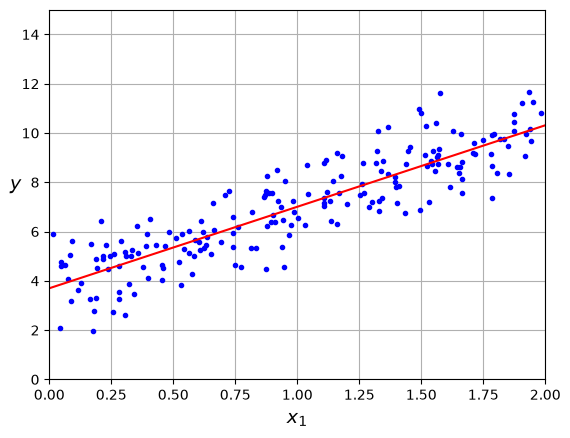

In [33]:
plt.plot(X, y, 'b.')
plt.plot(X_new,y_predict, 'r-', label='Prediction')

plt.xlabel('$x_1$')
plt.ylabel('$y$', rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()


In [34]:
#Batch Gradient Descent

In [35]:
theta_sgd = theta.copy()
J_log_sgd = J_log.copy()

In [36]:
eta_bgd = 0.1
n_epochs_bgd = 1000

In [37]:
rng = np.random.default_rng(seed=42)

theta_bgd = rng.standard_normal((2,1)) # mismo theta inicial que en SGD.
theta_bgd

array([[ 0.30471708],
       [-1.03998411]])

In [38]:
J_log_bgd = np.zeros(n_epochs_bgd)

for i in range(n_epochs_bgd):
    J_log_bgd[i] = (1/m)*((X_b@theta_bgd-y)**2).sum()

    gradients = (2/m) * X_b.T @ (X_b@theta_bgd - y) # aqui si uso todo X_b
    theta_bgd = theta_bgd - eta_bgd * gradients

theta_bgd

array([[3.69084138],
       [3.32960458]])

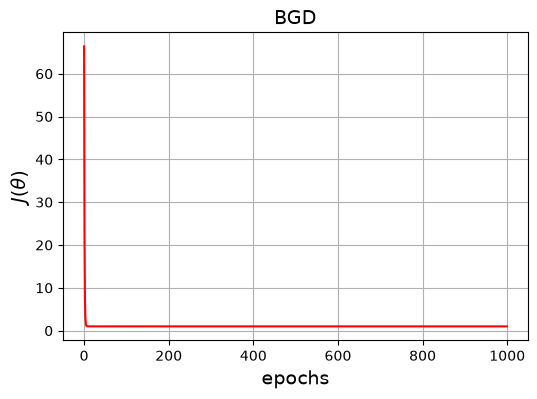

In [39]:
plt.figure(figsize=(6,4))

plt.plot(np.arange(n_epochs_bgd), J_log_bgd, 'r-')
plt.xlabel('epochs')
plt.ylabel(r'$J(\theta)$')
plt.title('BGD')
plt.grid(True)
plt.show()

In [40]:
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
J_min = ((X_b@theta_best - y)**2).mean()

theta_best

array([[3.69084138],
       [3.32960458]])

In [41]:
print('theta SGD:', theta_sgd.ravel())
print('theta BGD:', theta_bgd.ravel())
print('theta Normal Equation:', theta_best.ravel())
print()

theta SGD: [3.69826475 3.30748311]
theta BGD: [3.69084138 3.32960458]
theta Normal Equation: [3.69084138 3.32960458]

